# Fase 4 — Validación y Backtesting (Cap. 8)

Evaluación de pronóstico **out-of-sample one-step-ahead** sobre el test (2024–2026), comparando
el modelo SV Bayesiano contra benchmarks. La densidad predictiva de un paso del SV se obtiene con
un **filtro de partículas** (condicionado en el estado de volatilidad al final del train).

**Métricas** (`bayesian/sv_model/forecast_eval.py`):
- **Log-score** (log-verosimilitud predictiva, ↑ mejor)
- **CRPS** (Continuous Ranked Probability Score, ↓ mejor)
- **Coverage 95%** (objetivo 0.95) y **PIT** (calibración; Uniforme si está calibrado, test KS)

Comparamos: **SV (historia completa)**, **SV (ventana reciente)**, **GARCH(1,1)-t**, **Gaussiano i.i.d.**;
y replicamos el core en **ETH** como caso de contraste.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tesis.data import loader
from tesis.bayesian.sv_model.stochastic_volatility import fit_sv_pymc, idata_to_mcmc_result
from tesis.bayesian.sv_model.forecast_eval import (
    sv_particle_filter, garch_onestep_eval, gaussian_iid_eval, summarize_eval)
plt.style.use('seaborn-v0_8-whitegrid'); plt.rcParams['figure.figsize']=(12,4)
SEED=42

def fit_sv_meanparams(y, seed=SEED):
    idata=fit_sv_pymc(y, n_samples=1000, n_chains=4, target_accept=0.99, tune=2000, seed=seed)
    m=idata_to_mcmc_result(idata)
    return m, (m['mu'].mean(), m['phi'].mean(), m['sigma_eta'].mean())

## 1. BTC — datos y ajuste del SV (historia completa)

In [2]:
ret=loader.compute_log_returns(loader.load_price_series('BTC','1D'))
rtr,rte=loader.split_train_test(ret,'2024-01-01')
mu_ret=rtr.mean(); ytr=(rtr-mu_ret).values; yte=(rte-mu_ret).values
print(f'BTC train {len(ytr)} obs, test {len(yte)} obs ({rte.index.min().date()} -> {rte.index.max().date()})')
print(f'Vol. anualizada realizada en test: {yte.std()*np.sqrt(252):.1%}')

m_full, p_full = fit_sv_meanparams(ytr)
print(f'SV (full): mu={p_full[0]:.2f}, phi={p_full[1]:.3f}, sigma_eta={p_full[2]:.3f}')

BTC train 4382 obs, test 836 obs (2024-01-01 -> 2026-04-15)
Vol. anualizada realizada en test: 40.1%


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 809 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


SV (full): mu=-7.21, phi=0.903, sigma_eta=0.579


## 2. Evaluación one-step: SV vs GARCH vs i.i.d. (BTC)

In [3]:
res_sv = sv_particle_filter(yte, *p_full, n_particles=4000, h_init=m_full['h'][:,-1], seed=1)
res_g  = garch_onestep_eval(ytr, yte, seed=1)
res_i  = gaussian_iid_eval(ytr, yte, seed=1)

btc_rows=[summarize_eval('SV (full 2012-23)', res_sv),
          summarize_eval('GARCH(1,1)-t', res_g),
          summarize_eval('Gaussiano i.i.d.', res_i)]
btc_tab=pd.DataFrame(btc_rows).set_index('modelo')
print(btc_tab.to_string(float_format=lambda x:f'{x:.4f}'))
print(f"\nGARCH persistencia alpha+beta = {res_g['persistence']:.4f}, nu = {res_g['nu']:.1f}")

                   log_score   CRPS  coverage_95  PIT_KS_pvalue
modelo                                                         
SV (full 2012-23)     2.3007 0.0136       0.9641         0.0010
GARCH(1,1)-t          2.3198 0.0135       0.9438         0.0029
Gaussiano i.i.d.      2.0418 0.0154       0.9928         0.0000

GARCH persistencia alpha+beta = 1.0000, nu = 3.3


## 3. Calibración (PIT) y volatilidad predictiva

Si un modelo está calibrado, sus PIT son **Uniforme(0,1)** (histograma plano). También comparamos
la volatilidad predictiva de cada modelo contra la volatilidad realizada (rolling 21 d).

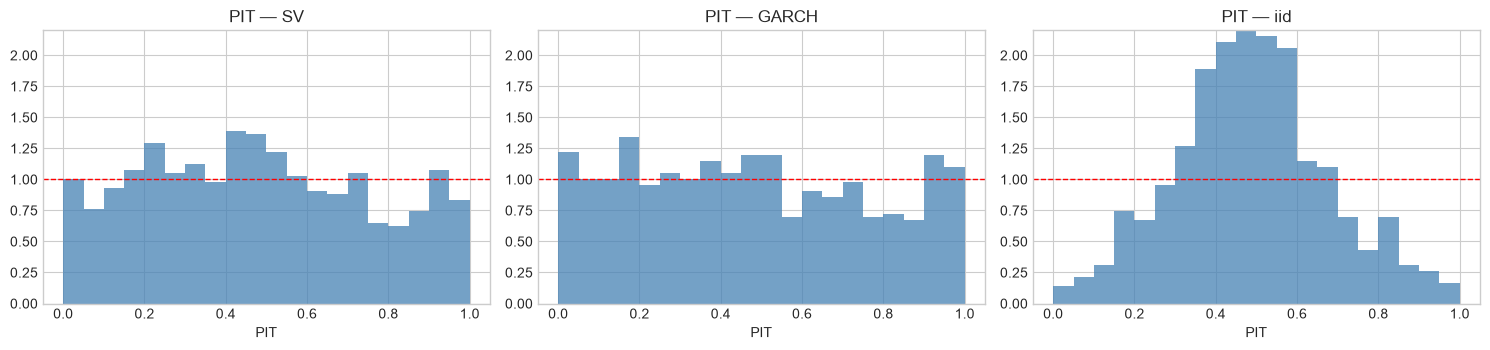

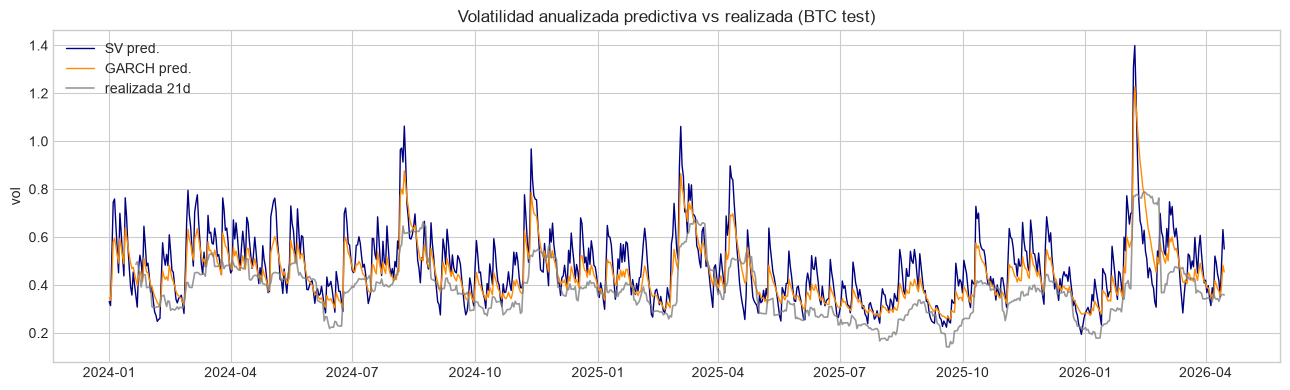

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,3.6))
for ax,(nm,r) in zip(axes, [('SV',res_sv),('GARCH',res_g),('iid',res_i)]):
    ax.hist(r['pit'], bins=20, range=(0,1), density=True, color='steelblue', alpha=0.75)
    ax.axhline(1.0, color='red', ls='--', lw=1)
    ax.set_title(f'PIT — {nm}'); ax.set_xlabel('PIT'); ax.set_ylim(0,2.2)
plt.tight_layout(); plt.show()

real_vol=pd.Series(yte, index=rte.index).rolling(21).std()*np.sqrt(252)
fig,ax=plt.subplots(figsize=(13,4))
ax.plot(rte.index, np.array(res_sv['pred_vol'])*np.sqrt(252), color='navy', lw=1, label='SV pred.')
ax.plot(rte.index, np.array(res_g['pred_vol'])*np.sqrt(252), color='darkorange', lw=1, label='GARCH pred.')
ax.plot(rte.index, real_vol, color='gray', lw=1.2, alpha=0.8, label='realizada 21d')
ax.set_title('Volatilidad anualizada predictiva vs realizada (BTC test)'); ax.legend(); ax.set_ylabel('vol')
plt.tight_layout(); plt.show()

## 4. Historia completa vs. ventana reciente (aborda la sobre-proyección)

En la Fase 3 el SV (2012–2023) sobre-proyecta la volatilidad reciente. ¿Mejora entrenar sobre una
**ventana reciente** (2021–2023)? Comparamos ambos en las mismas métricas one-step del test.

In [5]:
rtr_rec=rtr[rtr.index>='2021-01-01']; ytr_rec=(rtr_rec-rtr_rec.mean()).values
m_rec, p_rec = fit_sv_meanparams(ytr_rec)
res_rec=sv_particle_filter(yte, *p_rec, n_particles=4000, h_init=m_rec['h'][:,-1], seed=1)
print(f'SV (reciente 2021-23): mu={p_rec[0]:.2f}, phi={p_rec[1]:.3f}, sigma_eta={p_rec[2]:.3f}  (train {len(ytr_rec)} obs)')
cmp=pd.DataFrame([summarize_eval('SV full 2012-23', res_sv),
                  summarize_eval('SV reciente 2021-23', res_rec)]).set_index('modelo')
print(cmp.to_string(float_format=lambda x:f'{x:.4f}'))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 28 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


SV (reciente 2021-23): mu=-7.29, phi=0.871, sigma_eta=0.567  (train 1095 obs)
                     log_score   CRPS  coverage_95  PIT_KS_pvalue
modelo                                                           
SV full 2012-23         2.3007 0.0136       0.9641         0.0010
SV reciente 2021-23     2.3077 0.0136       0.9641         0.0011


## 5. Extensión a ETH (caso de contraste)

Replicamos el pipeline completo (ajuste SV + filtro + benchmarks) en ETH, sin re-tunear nada,
para verificar que el marco generaliza a otro cripto-activo.

In [6]:
ret_e=loader.compute_log_returns(loader.load_price_series('ETH','1D'))
etr,ete=loader.split_train_test(ret_e,'2024-01-01')
ytr_e=(etr-etr.mean()).values; yte_e=(ete-ete.mean()).values
print(f'ETH train {len(ytr_e)} obs, test {len(yte_e)} obs ({ete.index.min().date()} -> {ete.index.max().date()})')

m_e, p_e = fit_sv_meanparams(ytr_e)
res_sv_e=sv_particle_filter(yte_e, *p_e, n_particles=4000, h_init=m_e['h'][:,-1], seed=1)
res_g_e =garch_onestep_eval(ytr_e, yte_e, seed=1)
res_i_e =gaussian_iid_eval(ytr_e, yte_e, seed=1)
print(f'SV(ETH): mu={p_e[0]:.2f}, phi={p_e[1]:.3f}, sigma_eta={p_e[2]:.3f}')
eth_tab=pd.DataFrame([summarize_eval('SV', res_sv_e),
                      summarize_eval('GARCH(1,1)-t', res_g_e),
                      summarize_eval('Gaussiano i.i.d.', res_i_e)]).set_index('modelo')
print(eth_tab.to_string(float_format=lambda x:f'{x:.4f}'))

Initializing NUTS using jitter+adapt_diag...


ETH train 2328 obs, test 735 obs (2024-01-01 -> 2026-01-04)


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 46 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


SV(ETH): mu=-6.56, phi=0.904, sigma_eta=0.453
                  log_score   CRPS  coverage_95  PIT_KS_pvalue
modelo                                                        
SV                   1.9495 0.0193       0.9524         0.0894
GARCH(1,1)-t         1.9583 0.0193       0.9456         0.6412
Gaussiano i.i.d.     1.8194 0.0204       0.9755         0.0000


## 6. Resumen comparativo (BTC y ETH)

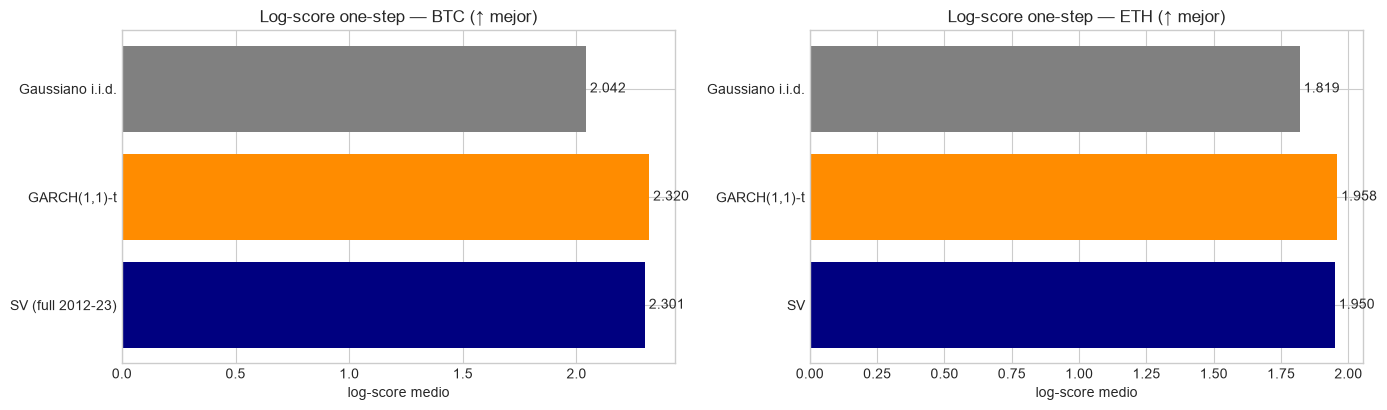

In [7]:
fig,axes=plt.subplots(1,2,figsize=(14,4.2))
for ax,(title,tab) in zip(axes, [('BTC',btc_tab),('ETH',eth_tab)]):
    ax.barh(tab.index, tab['log_score'], color=['navy','darkorange','gray'][:len(tab)])
    ax.set_title(f'Log-score one-step — {title} (↑ mejor)'); ax.set_xlabel('log-score medio')
    for i,v in enumerate(tab['log_score']): ax.text(v, i, f' {v:.3f}', va='center')
plt.tight_layout(); plt.show()

## 7. Conclusiones de la Fase 4

- **La volatilidad variable importa:** SV y GARCH superan claramente al Gaussiano i.i.d. en
  log-score y CRPS, tanto en BTC como en ETH → valida modelar la volatilidad condicional.
- **SV ≈ GARCH:** el SV Bayesiano es competitivo con GARCH(1,1)-t. GARCH queda marginalmente por
  encima en log-score/coverage; el SV **sobre-cubre** ligeramente (intervalos algo anchos),
  consistente con la sobre-proyección de volatilidad observada en la Fase 3.
- **Ventana reciente ≈ historia completa:** el filtro condiciona en los retornos realizados en cada
  paso, así que la elección de ventana de entrenamiento afecta poco el pronóstico one-step.
- **Calibración (PIT):** ningún modelo es perfectamente calibrado (KS bajo); el SV con densidad de
  observación **Gaussiana** subestima las colas → un **SV-t** (errores Student-t) es la mejora natural.
- **Generaliza a ETH:** el marco reproduce el mismo patrón cualitativo sin re-tunear.

**Trabajo futuro (Cap. 9):** SV con errores t / leverage (asimetría), particle-MCMC para propagar
incertidumbre paramétrica en el filtro, y evaluación con función de pérdida económica (costo de
liquidación) además de las métricas estadísticas.